# 01 — Exploratory Data Analysis

**Personal Tabular Machine Learning Handbook**


## Learning objectives
- Inspect a raw table, check data quality, and distinguish feature types.
- Describe distributions and relationships without confusing association with causation.
- Turn observations into explicit preprocessing and modeling decisions.

**Primary project:** Predict a store's monthly sales (IDR million) from promotional spending and region. This is regression because the target is a numerical amount. The supplied data contains store snapshots, not repeated dates; do not infer time trends.

**Before you run:** Notebook 00 is useful background. This notebook reads data/raw/nusantaramart_simple_sales.csv and can run independently. All modeling work continues in 02–04.

**How to use this notebook:** Read top to bottom the first time. Later, search for a `Technique:` heading or use the Quick Syntax Reference. Each code example is executable after its preceding setup cells. Outputs are included for revision.

## A. Introduction to EDA

EDA means investigating data before choosing a model. It helps discover patterns, investigate collection problems, and formulate hypotheses; it does not prove causes.

- **Univariate analysis:** One variable, such as the distribution of sales.
- **Bivariate analysis:** Two variables, such as promotional spending and sales.
- **Multivariate analysis:** Several variables together, such as the spending–sales relationship within each region.
- **Numerical feature:** A measured quantity such as spending.
- **Categorical feature:** A group label such as region. A numeric-looking ID can still be a label.
- **Target:** What we want to predict, here `monthly_sales_million`.

### Holdout discipline starts before exploratory modeling
We reserve test and validation records using a fixed split before inspecting outcomes. This notebook explores **only raw training rows**. Inspecting all target relationships and then choosing features can leak information from the test set into modeling decisions.

The split is 60% training, 20% validation, and 20% test, subject to integer rounding. Notebook 02 repeats it with the same seed. Random row splitting assumes stores are independent; use group- or time-based splits instead if deployment involves repeated stores or future periods.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

raw = pd.read_csv("data/raw/nusantaramart_simple_sales.csv", dtype={"store_id": "string", "region": "string"})
development, test_reserved = train_test_split(raw, test_size=0.20, random_state=42)
train_raw, validation_reserved = train_test_split(development, test_size=0.25, random_state=42)
df = train_raw.copy()
print("Train / validation / test rows:", len(df), len(validation_reserved), len(test_reserved))
del test_reserved, validation_reserved, development, raw  # explore training only below

Train / validation / test rows: 51 17 18


**Interpretation:** There are 51 training, 17 validation, and 18 test stores. The small sample makes comparisons uncertain. We do not use `store_id` as a predictor: it identifies records rather than a meaningful sales driver.

## B. Initial Data Inspection

### Technique: head, tail, sample, shape, and columns

**What is it?** These commands reveal examples, table size, and schema.

**Why do we use it?** Confirm that you loaded the intended table and know its unit of observation.

**When should we use it?** Use immediately after reading a new dataset.

**Python Syntax / Example**

The following cell is a runnable example; adapt the column names and values to reuse it.

In [2]:
display(df.head(), df.tail(2), df.sample(3, random_state=42))
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

,store_id,region,promo_spend_million,monthly_sales_million
65,NM-066,Sumatra,14.6,194.8
27,NM-028,Java,8.9,194.5
6,NM-007,Sumatra,33.3,349.0
43,NM-044,Sumatra,21.7,267.1
82,NM-083,Java,8.6,139.7


,store_id,region,promo_spend_million,monthly_sales_million
16,NM-017,Java,23.5,296.0
59,NM-060,Sumatra,11.5,187.1


,store_id,region,promo_spend_million,monthly_sales_million
25,NM-026,Java,15.1,222.6
47,NM-048,Java,31.7,360.8
46,NM-047,Java,27.4,317.5


Shape: (51, 4)
Columns: ['store_id', 'region', 'promo_spend_million', 'monthly_sales_million']


**Interpretation:** Each displayed row describes one training store. The first and last rows do not necessarily represent the full distribution; sample provides another view.

**Things to Remember:** A random sample of three rows is still too small for a reliable conclusion. The index preserves original row labels after splitting.

### Technique: info, dtypes, describe, nunique, and value_counts

**What is it?** Schema checks distinguish numeric columns, identifiers, categories, and missing entries.

**Why do we use it?** A model cannot interpret a number stored as text correctly without conversion.

**When should we use it?** Use before numerical summaries or chart selection.

**Python Syntax / Example**

The following cell is a runnable example; adapt the column names and values to reuse it.

In [3]:
df.info()
display(df.dtypes, df.describe(), df.nunique())
display(df["region"].value_counts(dropna=False))

<class 'pandas.core.frame.DataFrame'>
Index: 51 entries, 65 to 59
Data columns (total 4 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   store_id               51 non-null     string 
 1   region                 51 non-null     string 
 2   promo_spend_million    51 non-null     float64
 3   monthly_sales_million  51 non-null     float64
dtypes: float64(2), string(2)
memory usage: 2.0 KB


store_id                 string[python]
region                   string[python]
promo_spend_million             float64
monthly_sales_million           float64
dtype: object

,promo_spend_million,monthly_sales_million
count,51.000000,51.000000
mean,20.168627,254.168627
std,8.476638,69.768702
min,5.900000,122.400000
25%,13.800000,194.650000
50%,21.600000,267.100000
75%,26.950000,311.600000
max,33.900000,370.700000


store_id                 51
region                    2
promo_spend_million      46
monthly_sales_million    50
dtype: int64

region
Java       37
Sumatra    14
Name: count, dtype: Int64

**Interpretation:** The training data contains two money columns, a store ID, and region. Unique counts help identify IDs. describe summarizes numbers, not all text columns by default.

**Things to Remember:** Non-null counts do not detect impossible values or strings such as "unknown". Check semantics as well as dtypes.

## C. Data Quality Assessment

### Technique: Missing values and duplicate observations

**What is it?** Missingness is absent data; duplication is repeated records or repeated keys.

**Why do we use it?** Missing rows and double-counted stores can distort summaries and models.

**When should we use it?** Check full-row duplicates and business-key duplicates separately.

**Python Syntax / Example**

The following cell is a runnable example; adapt the column names and values to reuse it.

In [4]:
quality = pd.DataFrame({"missing_count": df.isna().sum(), "missing_fraction": df.isna().mean()})
display(quality)
print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate store IDs:", df["store_id"].duplicated().sum())

,missing_count,missing_fraction
store_id,0,0.0
region,0,0.0
promo_spend_million,0,0.0
monthly_sales_million,0,0.0


Exact duplicate rows: 0
Duplicate store IDs: 0


**Interpretation:** The printed counts are the evidence; in this supplied training subset they are zero. Multiple records per store would require a date/key definition before deciding whether they are duplicates.

**Things to Remember:** Never drop records solely because two numerical features match. Distinct stores can legitimately have identical measurements.

### Technique: Incorrect types, invalid numbers, and inconsistent categories

**What is it?** Quality rules test whether data matches business definitions.

**Why do we use it?** Nonmissing entries can still be invalid or inconsistently labeled.

**When should we use it?** Use domain-specific rules and normalize text only after checking intended categories.

**Python Syntax / Example**

The following cell is a runnable example; adapt the column names and values to reuse it.

In [5]:
numeric_cols = ["promo_spend_million", "monthly_sales_million"]
parsed = df[numeric_cols].apply(pd.to_numeric, errors="coerce")
print("Unparseable nonmissing entries:", (parsed.isna() & df[numeric_cols].notna()).sum().to_dict())
print("Negative values:", (parsed < 0).sum().to_dict())
print("Nonfinite observed numbers:", ((~np.isfinite(parsed)) & parsed.notna()).sum().to_dict())
normalized_regions = df["region"].str.strip().str.title()
print("Rows whose region needs normalization:", df["region"].ne(normalized_regions).sum())
print("Unexpected regions:", normalized_regions.loc[~normalized_regions.isin(["Java", "Sumatra"])].tolist())

Unparseable nonmissing entries: {'promo_spend_million': 0, 'monthly_sales_million': 0}
Negative values: {'promo_spend_million': 0, 'monthly_sales_million': 0}
Nonfinite observed numbers: {'promo_spend_million': 0, 'monthly_sales_million': 0}
Rows whose region needs normalization: 0
Unexpected regions: []


**Interpretation:** Zero flagged values indicate no violations of these particular rules, not a guarantee of data accuracy. Negative spending would be suspect here, but refunds may be valid in other datasets.

**Things to Remember:** errors="coerce" converts invalid text to NaN: count new missing entries rather than silently hiding them. A numeric ID should usually remain a string.

## D. Descriptive Statistics

### Technique: Mean, median, mode, variance, standard deviation, quantiles, IQR, and skewness

**What is it?** These summaries describe typical values, spread, and asymmetry.

**Why do we use it?** A single average cannot describe how differently stores perform.

**When should we use it?** Use median and quantiles alongside the mean, especially for skewed distributions.

**Python Syntax / Example**

The following cell is a runnable example; adapt the column names and values to reuse it.

In [6]:
sales = df["monthly_sales_million"]
statistics = sales.agg(["count", "mean", "median", "var", "std", "min", "max", "skew"])
display(statistics)
print("Mode(s):", sales.mode().tolist())
quantiles = sales.quantile([0.25, 0.50, 0.75, 0.90])
display(quantiles)
iqr = quantiles.loc[0.75] - quantiles.loc[0.25]
print(f"IQR: {iqr:.2f} million; 90th percentile: {np.percentile(sales, 90):.2f} million")

count       51.000000
mean       254.168627
median     267.100000
var       4867.671796
std         69.768702
min        122.400000
max        370.700000
skew        -0.204358
Name: monthly_sales_million, dtype: float64

Mode(s): [180.2]


0.25    194.65
0.50    267.10
0.75    311.60
0.90    341.50
Name: monthly_sales_million, dtype: float64

IQR: 116.95 million; 90th percentile: 341.50 million


**Interpretation:** Mean is the arithmetic average; median is the middle; mode is the most frequent value and may have ties. Variance has squared units; standard deviation has sales units. The IQR spans the middle 50%. Positive skew suggests a longer right tail; negative skew a longer left tail.

**Things to Remember:** With continuous measurements, many modes may be uninformative. Pandas uses sample variance by default. Quantiles summarize observed data, not guaranteed future bounds.

## E. Data Visualization

Every chart below asks a question about training stores. Its code is followed by the interpretation; printed summaries provide the exact numerical evidence.

### Technique: Histogram and boxplot

**What is it?** A histogram counts values within ranges; a boxplot compresses the median, quartiles, and unusual values.

**Why do we use it?** They reveal spread that an average conceals.

**When should we use it?** Use both to inspect one numerical feature or target.

**Python Syntax / Example**

The following cell is a runnable example; adapt the column names and values to reuse it.

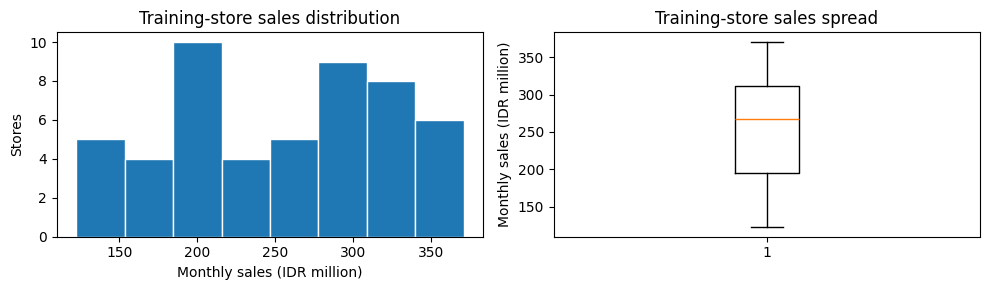

Training sales: min 122.40, median 267.10, max 370.70


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].hist(sales, bins=8, edgecolor="white")
axes[0].set(title="Training-store sales distribution", xlabel="Monthly sales (IDR million)", ylabel="Stores")
axes[1].boxplot(sales)
axes[1].set(title="Training-store sales spread", ylabel="Monthly sales (IDR million)")
fig.tight_layout()
plt.show()
print(f"Training sales: min {sales.min():.2f}, median {sales.median():.2f}, max {sales.max():.2f}")

**Interpretation:** The histogram shows the shape; the box spans the middle half of stores. Read the printed range and median with the chart. Different bin widths can change the apparent shape.

**Things to Remember:** A boxplot whisker is not a guaranteed minimum/maximum. Points beyond whiskers are not automatically errors.

### Technique: Regional bar chart and distribution comparisons

**What is it?** A bar compares group summaries; grouped boxplots compare their distributions.

**Why do we use it?** Close means can conceal different spread or group sizes.

**When should we use it?** Compare categories with counts and distribution context.

**Python Syntax / Example**

The following cell is a runnable example; adapt the column names and values to reuse it.

,count,mean,median
region,,,
Java,37,251.61,268.0
Sumatra,14,260.92,264.4


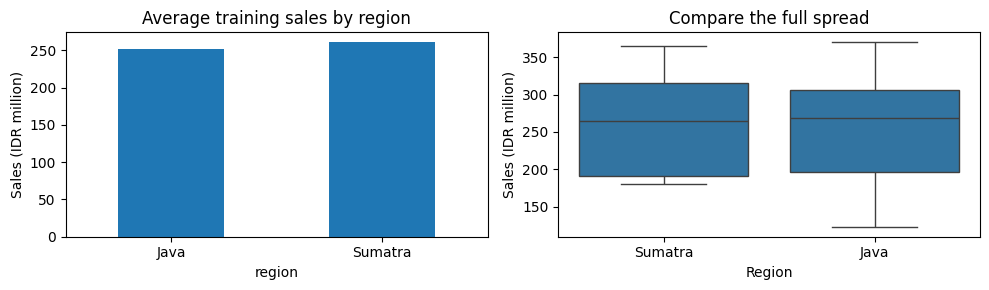

In [8]:
regional = df.groupby("region")["monthly_sales_million"].agg(["count", "mean", "median"])
display(regional.round(2))
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
regional["mean"].plot.bar(ax=axes[0], rot=0)
axes[0].set(title="Average training sales by region", ylabel="Sales (IDR million)")
sns.boxplot(data=df, x="region", y="monthly_sales_million", ax=axes[1])
axes[1].set(title="Compare the full spread", xlabel="Region", ylabel="Sales (IDR million)")
fig.tight_layout()
plt.show()

**Interpretation:** The table reports the actual regional training means and store counts. The boxplots show overlapping sales ranges: a larger regional mean does not establish better management.

**Things to Remember:** The training split has 37 Java and 14 Sumatra stores. Small groups give unstable summaries; these are not full-dataset regional estimates.

### Technique: Scatter plot and multivariate comparison

**What is it?** A scatter plot shows paired numerical observations; color adds a category.

**Why do we use it?** It helps identify a relationship and whether it looks different by segment.

**When should we use it?** Use when checking whether a proposed predictor relates to a numeric target.

**Python Syntax / Example**

The following cell is a runnable example; adapt the column names and values to reuse it.

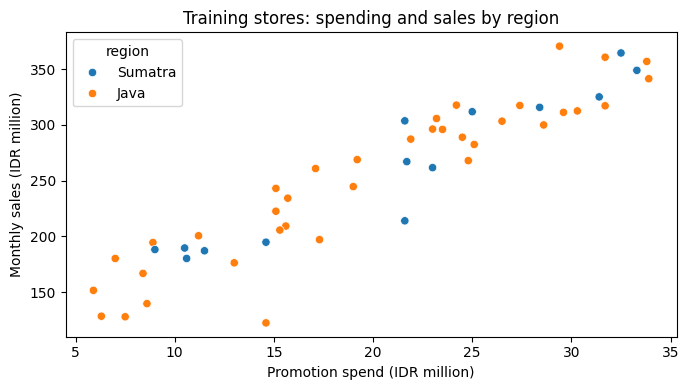

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.scatterplot(data=df, x="promo_spend_million", y="monthly_sales_million", hue="region", ax=ax)
ax.set(title="Training stores: spending and sales by region", xlabel="Promotion spend (IDR million)", ylabel="Monthly sales (IDR million)")
fig.tight_layout()
plt.show()

**Interpretation:** Read from left to right: the upward cloud suggests that higher-spending stores tend to sell more. Color allows a visual comparison within regions; it does not control for unobserved differences.

**Things to Remember:** Larger stores might both spend and sell more. This cross-sectional scatter cannot estimate the causal effect of a budget increase.

## F. Correlation Analysis

### Technique: Pearson, Spearman, correlation matrices, and heatmaps

**What is it?** Pearson summarizes a linear relationship; Spearman summarizes a monotonic relationship using ranks.

**Why do we use it?** They quantify direction and strength without requiring a chart for every pair.

**When should we use it?** Use Pearson for straight-line associations and Spearman when the relationship is ordered but not necessarily linear.

**Python Syntax / Example**

The following cell is a runnable example; adapt the column names and values to reuse it.

,promo_spend_million,monthly_sales_million
promo_spend_million,1.00000,0.93657
monthly_sales_million,0.93657,1.00000


,promo_spend_million,monthly_sales_million
promo_spend_million,1.000000,0.944201
monthly_sales_million,0.944201,1.000000


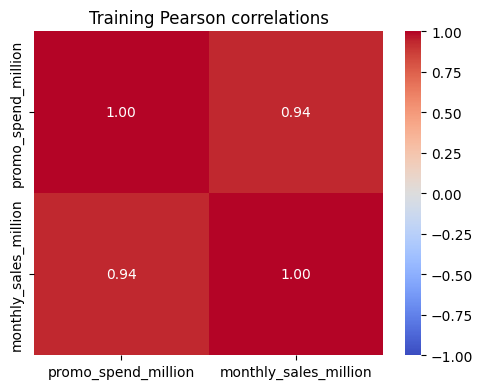

In [10]:
numeric = df[["promo_spend_million", "monthly_sales_million"]]
pearson = numeric.corr(method="pearson")
spearman = numeric.corr(method="spearman")
display(pearson, spearman)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(pearson, annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="coolwarm", ax=ax)
ax.set_title("Training Pearson correlations")
fig.tight_layout()
plt.show()

**Interpretation:** Values near +1 indicate a strong positive relationship and near −1 a strong negative one. A value near 0 indicates little of the measured relationship, not necessarily no relationship at all. The diagonal is 1 because each variable matches itself.

**Things to Remember:** Correlation is not causation. Outliers and narrow ranges can change it. Multicollinearity means predictors contain overlapping information, which can make linear coefficients unstable; our primary input has only one numerical predictor, so there is no numerical predictor pair to filter here.

### Technique: IQR flags for unusual observations

**What is it?** An IQR rule flags values below Q1 − 1.5×IQR or above Q3 + 1.5×IQR.

**Why do we use it?** It creates a review list rather than automatically discarding extreme stores.

**When should we use it?** Use as a univariate screening heuristic, followed by domain investigation.

**Python Syntax / Example**

The following cell is a runnable example; adapt the column names and values to reuse it.

In [11]:
q1, q3 = sales.quantile([0.25, 0.75])
low, high = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
unusual = df.loc[(sales < low) | (sales > high)]
print(f"Review bounds: {low:.2f} to {high:.2f} million; flagged stores: {len(unusual)}")
display(unusual)

Review bounds: 19.22 to 487.03 million; flagged stores: 0


,store_id,region,promo_spend_million,monthly_sales_million


**Interpretation:** A flag means unusual under this rule. No flags would mean the rule found none, not that every relationship is ordinary.

**Things to Remember:** A store can be unusual relative to its spending even when its sales are not an extreme on their own. Never remove test rows to improve a score.

## G. EDA Findings and Their Modeling Consequences

This cell prints dataset-specific findings directly from training data. Use these outputs when writing your own summary instead of copying findings from another dataset.

In [12]:
print(f"Training records: {len(df)}; missing cells: {df.isna().sum().sum()}; duplicate IDs: {df.store_id.duplicated().sum()}")
print(f"Sales mean / median: {sales.mean():.2f} / {sales.median():.2f} million IDR")
print(f"Spending–sales Pearson: {pearson.loc['promo_spend_million', 'monthly_sales_million']:.3f}")
print("Regional training summary:")
display(regional.round(2))

Training records: 51; missing cells: 0; duplicate IDs: 0
Sales mean / median: 254.17 / 267.10 million IDR
Spending–sales Pearson: 0.937
Regional training summary:


,count,mean,median
region,,,
Java,37,251.61,268.0
Sumatra,14,260.92,264.4


**Interpretation → decision:**
- Store IDs identify observations, so exclude them from predictors but retain them for traceability and split checks.
- There are no missing training values under these checks. Learn imputation inside a pipeline anyway so inference is robust to an occasional missing field; missing-value lessons in 02 use explicitly constructed examples.
- Region is categorical: encode it rather than assigning an arbitrary numeric order.
- The positive spending–sales pattern motivates a simple linear baseline alongside tree models. It does not guarantee any algorithm will generalize.
- The small training set argues for simple models, cross-validation, and cautious conclusions. Region comparisons do not control for store size, competition, or profit margins.
- Do not engineer features from the target or use sales-derived ratios as predictors of sales.

## Quick Syntax Reference

| Question | Syntax |
|---|---|
| What is in the table? | `df.head()`, `df.tail()`, `df.sample(3, random_state=42)` |
| What schema? | `df.shape`, `df.columns`, `df.info()`, `df.dtypes` |
| How many distinct values? | `df.nunique()` |
| Category frequencies? | `df["region"].value_counts(dropna=False)` |
| Missing / duplicates? | `df.isna().sum()`, `df.duplicated().sum()` |
| Central value and spread? | `s.mean()`, `s.median()`, `s.mode()`, `s.var()`, `s.std()` |
| Quantile / asymmetry? | `s.quantile(.75)`, `s.skew()` |
| Linear / ranked association? | `numeric.corr(method="pearson")`, `numeric.corr(method="spearman")` |
| Distribution / categories? | `ax.hist(s)`, `ax.boxplot(s)`, `series.plot.bar(ax=ax)` |
| Correlation heatmap? | `sns.heatmap(numeric.corr(), annot=True)` |

## Reusable EDA Checklist
- [ ] Define the business decision, unit of observation, prediction time, target, and units.
- [ ] Reserve holdouts before outcome-driven exploration; check time/group leakage.
- [ ] Inspect schema, target availability, duplicates, missingness, valid ranges, and categories.
- [ ] Examine central values, spread, distributions, and unusual observations.
- [ ] Compare groups with counts and context; inspect relationships without causal claims.
- [ ] Record hypotheses and preprocessing choices; preserve raw data.

## Practice exercises
1. Compare spending median and mean in the training table. Would either summary hide store variation? Justify with a distribution plot.
2. Calculate spending–sales Spearman correlation separately by region. Report each group's size and explain why a small sample weakens certainty.
3. Write three EDA observations and one modeling implication for each. **Check:** every numerical claim must be reproducible from `df`, and no conclusion may use held-out outcomes.